<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-10/lab-057-ghz-w-dicke-target-states.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 057 — GHZ, W and Dicke target states

A six-qubit register starts in $|000000\rangle$. We want to bring it to a chosen target state $|\psi_{\rm target}\rangle$ by applying a sequence of allowed operations. A prepared state $|\psi\rangle$ is judged by its fidelity $F=|\langle\psi_{\rm target}|\psi\rangle|^2$, which equals one for a perfect preparation and is the reward signal used by the compilation agents of the lecture.

We first introduce the available operations with their matrices and Hamiltonian forms. We then define the three targets, GHZ, W and Dicke, and compare their amplitudes, excitation numbers, entanglement and response to losing a qubit. Only then do we build reference circuits for GHZ and W from the introduced operations.

This notebook uses exact state vectors with NumPy, SciPy and Matplotlib. It trains no reinforcement-learning agent and reports no new compilation benchmark. The Dicke state is an additional target for future compilation experiments.

## Operations on qubits

Each qubit has basis states $|0\rangle$ and $|1\rangle$. In a basis string $|x_0x_1\dots x_5\rangle$ qubit 0 is the most significant bit. The Pauli matrices are
$$\hat X=\begin{pmatrix}0&1\\1&0\end{pmatrix},\qquad \hat Y=\begin{pmatrix}0&-i\\ i&0\end{pmatrix},\qquad \hat Z=\begin{pmatrix}1&0\\0&-1\end{pmatrix}.$$

Every operation is a unitary matrix, and every unitary is the time evolution $e^{-i\hat{\mathcal H} t}$ under some Hamiltonian $\hat{\mathcal H}$ acting for a time $t$, with $\hbar=1$. Hardware implements a gate by switching on such a Hamiltonian, so we give both forms.

### Single-qubit gates

The Hadamard gate maps $|0\rangle\to(|0\rangle+|1\rangle)/\sqrt2$ and $|1\rangle\to(|0\rangle-|1\rangle)/\sqrt2$. It creates an equal superposition from a basis state. The phase gates S and T leave $|0\rangle$ unchanged and multiply $|1\rangle$ by a phase,
$$\hat H=\frac1{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix}=e^{-i\pi(\hat I-\hat H)/2},\qquad \hat S=\begin{pmatrix}1&0\\0&i\end{pmatrix}=e^{i\pi/4}e^{-i\pi \hat Z/4},\qquad \hat T=\begin{pmatrix}1&0\\0&e^{i\pi/4}\end{pmatrix}=e^{i\pi/8}e^{-i\pi \hat Z/8}.$$
A rotation by a continuous angle $\theta$ about the axis $\alpha\in\{x,y,z\}$ is
$$\hat R_\alpha(\theta)=e^{-i\theta\hat\sigma_\alpha/2}=\cos\tfrac\theta2\,\hat I-i\sin\tfrac\theta2\,\hat\sigma_\alpha ,$$
with $\hat\sigma_x=\hat X$, $\hat\sigma_y=\hat Y$, $\hat\sigma_z=\hat Z$. It is generated by the field term $\hat{\mathcal H}=\tfrac\Omega2\hat\sigma_\alpha$ acting for the time $t=\theta/\Omega$.

### Two-qubit gates

The controlled-NOT gate (CNOT) flips the second (target) qubit when the first (control) qubit is $|1\rangle$. In the basis $|00\rangle,|01\rangle,|10\rangle,|11\rangle$,
$$\widehat{\mathrm{CNOT}}=\begin{pmatrix}1&0&0&0\\0&1&0&0\\0&0&0&1\\0&0&1&0\end{pmatrix}=e^{-i\pi(\hat I-\hat Z)\otimes(\hat I-\hat X)/4}.$$
The operator $(\hat I-\hat Z)/2$ projects the control on $|1\rangle$ and $(\hat I-\hat X)/2$ has eigenvalue one on the target state that X flips, which is why this product generates the flip. The continuous two-qubit rotations
$$\hat R_{\alpha\alpha}(\theta)=e^{-i\theta\,\hat\sigma_\alpha\otimes\hat\sigma_\alpha/2}=\cos\tfrac\theta2\,\hat I-i\sin\tfrac\theta2\,\hat\sigma_\alpha\otimes\hat\sigma_\alpha$$
are generated by the Ising-type couplings $\hat{\mathcal H}=\tfrac J2\hat\sigma_\alpha\otimes\hat\sigma_\alpha$ (XX, YY and ZZ interactions) acting for $t=\theta/J$. Only the two-qubit operations can create entanglement.

The cell below checks every matrix against its exponential form. It also checks that the excitation-transfer gate used later for the W state, $\hat G(\theta)=(\hat I\otimes \hat S)\,\hat R_{xx}(\theta)\hat R_{yy}(\theta)\,(\hat I\otimes \hat S)^\dagger$, rotates $|01\rangle$ and $|10\rangle$ into each other by the angle $\theta$ and leaves $|00\rangle$ and $|11\rangle$ unchanged. The helper functions apply a one- or two-qubit matrix to chosen qubits of the register.

In [1]:
from math import comb
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

N = 6
I = np.eye(2)
X = np.array([[0,1],[1,0]],dtype=complex)
Y = np.array([[0,-1j],[1j,0]])
Z = np.diag([1.0,-1.0]).astype(complex)
H = (X+Z)/np.sqrt(2)
S = np.diag([1,1j])
T = np.diag([1,np.exp(1j*np.pi/4)])
CX = np.array([[1,0,0,0],[0,1,0,0],[0,0,0,1],[0,0,1,0]],dtype=complex)

def R(pauli, theta):
    return expm(-1j*theta*pauli/2)
def R2(pauli, theta):
    return expm(-1j*theta*np.kron(pauli,pauli)/2)
def transfer_gate(theta):
    phases = np.kron(I,S)
    return phases@R2(X,theta)@R2(Y,theta)@phases.conj().T

assert np.allclose(H, expm(-1j*np.pi*(I-H)/2))
assert np.allclose(S, np.exp(1j*np.pi/4)*expm(-1j*np.pi*Z/4))
assert np.allclose(T, np.exp(1j*np.pi/8)*expm(-1j*np.pi*Z/8))
assert np.allclose(CX, expm(-1j*np.pi*np.kron(I-Z,I-X)/4))
for theta in (0, 0.3, np.pi/2, np.pi, 2*np.pi):
    c2, s2 = np.cos(theta/2), np.sin(theta/2)
    for pauli in (X,Y,Z):
        assert np.allclose(R(pauli,theta), c2*I-1j*s2*pauli)
        assert np.allclose(R2(pauli,theta), c2*np.eye(4)-1j*s2*np.kron(pauli,pauli))
    c, s = np.cos(theta), np.sin(theta)
    expected = np.array([[1,0,0,0],[0,c,s,0],[0,-s,c,0],[0,0,0,1]])
    assert np.allclose(transfer_gate(theta), expected)
basis = np.eye(4)
print("CNOT on 00,01,10,11 gives", [format(int(np.argmax(abs(CX@e))),'02b') for e in basis])
print("H, S, T, rotation, CNOT and transfer-gate identities pass.")

def apply_1q(v, U, q, n=N):
    psi = np.moveaxis(v.reshape([2]*n), q, 0)
    psi = np.tensordot(U, psi, axes=(1,0))
    return np.moveaxis(psi, 0, q).reshape(-1)
def apply_2q(v, U, q1, q2, n=N):
    psi = np.moveaxis(v.reshape([2]*n), (q1,q2), (0,1))
    psi = np.tensordot(U.reshape(2,2,2,2), psi, axes=((2,3),(0,1)))
    return np.moveaxis(psi, (0,1), (q1,q2)).reshape(-1)

CNOT on 00,01,10,11 gives ['00', '01', '11', '10']
H, S, T, rotation, CNOT and transfer-gate identities pass.


## Three target superpositions

The excitation number $|x|$ of a basis string is its number of 1s. The three targets are
$$|\mathrm{GHZ}_6\rangle=\frac{|000000\rangle+|111111\rangle}{\sqrt2},\qquad |W_6\rangle=\frac{|100000\rangle+|010000\rangle+\dots+|000001\rangle}{\sqrt6},\qquad |D_6^{(3)}\rangle=\frac1{\sqrt{20}}\sum_{|x|=3}|x\rangle .$$
The GHZ state superposes the two strings in which all qubits agree. The W state is an equal positive superposition of the six strings with one excitation. The Dicke state is an equal positive superposition of all $\binom63=20$ strings with three excitations, each with amplitude $1/\sqrt{20}\approx0.224$. W and Dicke states have a fixed excitation number and are invariant under exchanges of qubits.

These states are coherent superpositions. Replacing them by a classical mixture with the same computational-basis probabilities removes relative-phase information. The cell below builds the three vectors and checks normalisation and the number of nonzero amplitudes.

In [2]:
strings = [format(i, f"0{N}b") for i in range(2**N)]
weights = np.array([s.count("1") for s in strings])
def dicke(n, k):
    assert 0 <= k <= n
    return np.array([1/np.sqrt(comb(n,k)) if i.bit_count()==k else 0.0
                     for i in range(2**n)])
ghz = np.zeros(2**N); ghz[0] = ghz[-1] = 1/np.sqrt(2)
w = dicke(N,1)
d3 = dicke(N,3)
states = {"GHZ6":ghz,"W6":w,"Dicke6,3":d3}
for name, v in states.items():
    assert np.isclose(v@v,1)
    print(name, "nonzero amplitudes", np.count_nonzero(v),
          "values", np.unique(v[v!=0]))

GHZ6 nonzero amplitudes 2 values [0.70710678]
W6 nonzero amplitudes 6 values [0.40824829]
Dicke6,3 nonzero amplitudes 20 values [0.2236068]


The histograms show the probability of each excitation number. GHZ splits equally between 0 and 6 excitations, W sits at one excitation and the Dicke state at three.

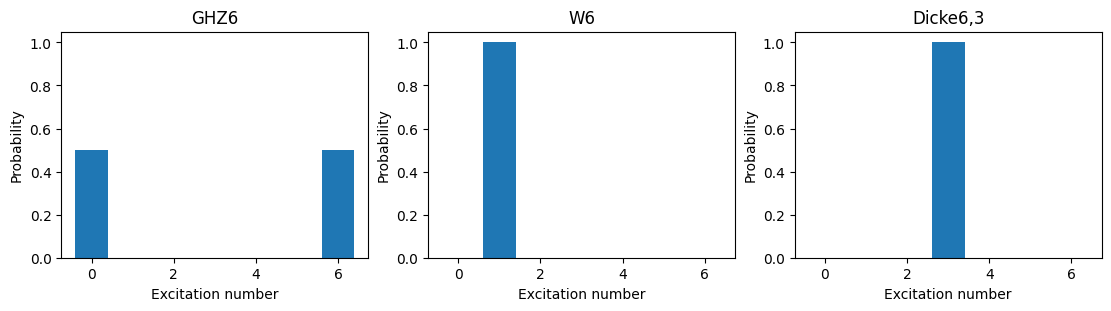

In [3]:
fig, axes = plt.subplots(1,3,figsize=(11,3),layout="constrained")
for ax,(name,v) in zip(axes,states.items()):
    distribution = np.bincount(weights,weights=np.abs(v)**2,minlength=N+1)
    ax.bar(np.arange(N+1),distribution)
    ax.set(title=name,xlabel="Excitation number",ylabel="Probability",ylim=(0,1.05))
plt.show()
assert np.count_nonzero(d3)==20

## Entanglement across a cut
Divide the qubits into parts A and B and arrange the amplitudes as a matrix, with A's basis states labelling rows and B's basis states labelling columns. A singular-value decomposition writes this matrix in orthogonal basis directions with nonnegative coefficients. These are the Schmidt coefficients. One nonzero coefficient describes a product state. More than one means that the pure state is entangled across that cut.

Ignoring B gives a reduced density matrix with entries $(\rho_A)_{ij}=\sum_b\psi_{ib}\psi^*_{jb}$. Summing out the unobserved index is the partial trace. The squared Schmidt coefficients $p_j$ sum to one. They are the eigenvalues of the reduced density matrix, and their entropy is $-\sum_jp_j\log_2p_j$. The notes derive the reduced-state rule before applying it to these targets.

In [4]:
def cut_entropy(v, left):
    coefficients = np.linalg.svd(v.reshape(2**left,-1),compute_uv=False)
    p = coefficients**2; p = p[p>1e-14]
    return float(-np.sum(p*np.log2(p)))
for name,v in states.items():
    entropies = [cut_entropy(v,left) for left in (1,2,3)]
    print(name, "entropy for cuts 1|5, 2|4, 3|3",np.round(entropies,6))
    assert all(x>0 for x in entropies)

GHZ6 entropy for cuts 1|5, 2|4, 3|3 [1. 1. 1.]
W6 entropy for cuts 1|5, 2|4, 3|3 [0.650022 0.918296 1.      ]
Dicke6,3 entropy for cuts 1|5, 2|4, 3|3 [1.       1.370951 1.468996]


## Predictions from excitation counting
For a cut with $m$ qubits on the left, group the Dicke strings by the number $j$ of excitations on that side. Each group contributes one Schmidt term, and its probability is the fraction of the $\binom Nk$ strings in the group, $p_j=\binom mj\binom{N-m}{k-j}/\binom Nk$. We compare these probabilities with the squared singular values of the target reshaped across the cut, for the 2|4 and 3|3 cuts of $|D_6^{(3)}\rangle$. The counting reproduces the entropies printed above without a numerical decomposition.

In [5]:
k = 3
for m in (2, 3):
    js = range(max(0,k-N+m), min(k,m)+1)
    predicted = np.array([comb(m,j)*comb(N-m,k-j)/comb(N,k) for j in js])
    spectrum = np.linalg.svd(d3.reshape(2**m,-1),compute_uv=False)**2
    assert np.allclose(np.sort(predicted),np.sort(spectrum[spectrum>1e-12]))
    assert np.isclose(predicted.sum(),1)
    print(f'cut {m}|{N-m}: Schmidt probabilities',predicted,
          'entropy in bits',round(float(-np.sum(predicted*np.log2(predicted))),6))

cut 2|4: Schmidt probabilities [0.2 0.6 0.2] entropy in bits 1.370951
cut 3|3: Schmidt probabilities [0.05 0.45 0.45 0.05] entropy in bits 1.468996


## Losing a qubit
We apply the partial-trace rule above to discard the first qubit. A reduced state can be mixed even when the whole register has one state vector.

Discarding the first qubit of GHZ leaves $\tfrac12\big(|00000\rangle\langle00000|+|11111\rangle\langle11111|\big)$. This is a classical mixture of two product states, so the remaining five qubits carry no entanglement at all. W leaves a mixture of $|W_5\rangle$ and the five-qubit vacuum with weights $5/6$ and $1/6$. Its dominant part is still the entangled $|W_5\rangle$, and the optional diagnostic at the end certifies that this mixture remains entangled. We check both reduced states directly and print their purities $\mathrm{Tr}\,\hat\rho^2$, which equal one only for a pure state.

In [6]:
def lose_first_qubit(v):
    branches=v.reshape(2,-1)
    return branches.T@branches.conj()
for name,v in states.items():
    rho=lose_first_qubit(v)
    assert np.isclose(np.trace(rho),1)
    print(name,'reduced-state purity',round(float(np.trace(rho@rho).real),6))
zeros5=np.zeros(32); zeros5[0]=1
ones5=np.zeros(32); ones5[-1]=1
assert np.allclose(lose_first_qubit(ghz),0.5*np.outer(zeros5,zeros5)+0.5*np.outer(ones5,ones5))
rho_w=lose_first_qubit(w)
w5=dicke(5,1)
assert np.allclose(rho_w,5/6*np.outer(w5,w5)+1/6*np.outer(zeros5,zeros5))
print("GHZ leaves a mixture of two product states; W leaves 5/6 W5 + 1/6 vacuum.")

GHZ6 reduced-state purity 0.5
W6 reduced-state purity 0.722222
Dicke6,3 reduced-state purity 0.5
GHZ leaves a mixture of two product states; W leaves 5/6 W5 + 1/6 vacuum.


## Entanglement created by two-qubit rotations

Single-qubit gates act on each qubit separately and cannot change the Schmidt coefficients across any cut. Entanglement must therefore come from the two-qubit operations. An XX rotation on $|00\rangle$ gives $\hat R_{xx}(\theta)|00\rangle=\cos\tfrac\theta2|00\rangle-i\sin\tfrac\theta2|11\rangle$ and transfers population to $|11\rangle$. A ZZ rotation on $|{+}{+}\rangle$, with $|{+}\rangle=(|0\rangle+|1\rangle)/\sqrt2$, leaves every computational-basis probability unchanged but creates entanglement through relative phases. We plot the transferred population and the entanglement entropy of the two resulting pure states.

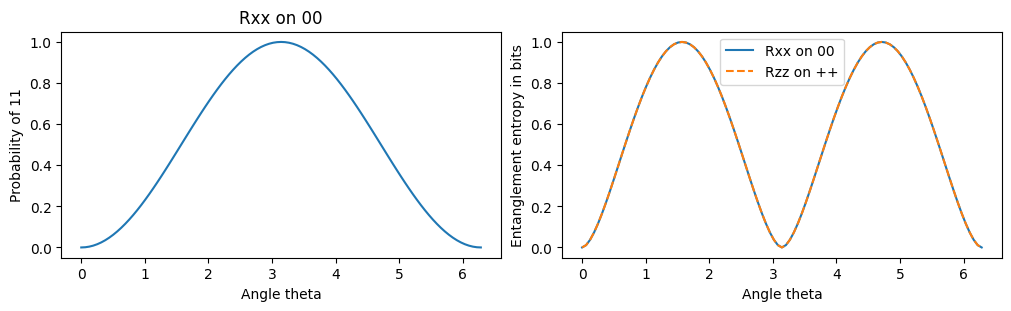

In [7]:
angles = np.linspace(0,2*np.pi,101)
zero2 = np.array([1,0,0,0],dtype=complex)
plus2 = np.ones(4)/2
population,entropy_xx,entropy_zz = [],[],[]
for angle in angles:
    vx = expm(-1j*angle*np.kron(X,X)/2)@zero2
    vz = expm(-1j*angle*np.kron(Z,Z)/2)@plus2
    population.append(abs(vx[3])**2)
    entropy_xx.append(cut_entropy(vx,1))
    entropy_zz.append(cut_entropy(vz,1))
fig,axes = plt.subplots(1,2,figsize=(10,3),layout="constrained")
axes[0].plot(angles,population)
axes[0].set(xlabel="Angle theta",ylabel="Probability of 11",title="Rxx on 00")
axes[1].plot(angles,entropy_xx,label="Rxx on 00")
axes[1].plot(angles,entropy_zz,ls="--",label="Rzz on ++")
axes[1].set(xlabel="Angle theta",ylabel="Entanglement entropy in bits")
axes[1].legend();plt.show()

Both states have Schmidt probabilities $\cos^2\tfrac\theta2$ and $\sin^2\tfrac\theta2$, so the two entropy curves coincide. The entanglement reaches one bit at $\theta=\pi/2$, where $\hat R_{xx}(\pi/2)|00\rangle=(|00\rangle-i|11\rangle)/\sqrt2$ becomes the two-qubit GHZ state $(|00\rangle+|11\rangle)/\sqrt2$ after the phase gate $\hat S$ on one qubit, and vanishes again at $\theta=\pi$.

## A reference circuit for GHZ6

The initial state is $|000000\rangle$, the target is $|\mathrm{GHZ}_6\rangle$, the allowed operations are H and CNOT, and success means fidelity $F=1$ up to rounding. The Hadamard on qubit 0 creates two coherent branches, $(|0\rangle+|1\rangle)|00000\rangle/\sqrt2$. Each CNOT copies the value of its control into the next qubit, so the branch $|1\rangle|00000\rangle$ becomes $|111111\rangle$ after five neighbouring CNOTs while $|000000\rangle$ is unchanged.

```
q0: ─H──●──────────────────
q1: ────X──●───────────────
q2: ───────X──●────────────
q3: ──────────X──●─────────
q4: ─────────────X──●──────
q5: ────────────────X──────
```

The circuit uses one H and five CNOT gates in six layers. This is an analytic reference construction. Shallower circuits are not tested here.

In [8]:
v = np.zeros(2**N); v[0] = 1
v = apply_1q(v, H, 0)
for q in range(N-1):
    v = apply_2q(v, CX, q, q+1)
assert np.allclose(v,ghz)
print("GHZ reference: 1 H + 5 CNOT, fidelity", round(float(abs(ghz@v)**2),12))

GHZ reference: 1 H + 5 CNOT, fidelity 1.0


## A continuous reference construction for W6

The initial state is $|000000\rangle$ and the target is $|W_6\rangle$. An X gate on qubit 0 places one excitation there, giving $|100000\rangle$. The transfer gate $\hat G(\theta)$ introduced above sends $|10\rangle$ to $\cos\theta|10\rangle+\sin\theta|01\rangle$ and $|01\rangle$ to $-\sin\theta|10\rangle+\cos\theta|01\rangle$. It preserves $|00\rangle$ and $|11\rangle$ and therefore conserves the excitation number. On bond $(j,j+1)$, for $j=0,\dots,4$, choose $\cos\theta_j=1/\sqrt{6-j}$. Each gate leaves amplitude $1/\sqrt6$ on qubit $j$ and moves the remaining amplitude one qubit to the right.

The construction uses one X gate and five transfer gates, each built from one XX rotation, one YY rotation and the phase gates $\hat S$ and $\hat S^\dagger$. Success again means $F=1$ up to rounding. This is an analytic reference construction with continuous angles.

In [9]:
v = np.zeros(2**N); v[0] = 1
v = apply_1q(v, X, 0)
for j in range(N-1):
    theta = np.arccos(1/np.sqrt(6-j))
    v = apply_2q(v, transfer_gate(theta), j, j+1)
assert np.allclose(v,w)
print("W reference: 1 X + 5 transfer gates, fidelity", round(float(abs(w@v)**2),12))

W reference: 1 X + 5 transfer gates, fidelity 1.0


## Compilation experiments

Use these exact vectors as fidelity targets. A learned circuit must be evaluated against the target appropriate to that run, with the allowed gate set and resource budget stated. The continuous W construction above and a discrete H,S,T,CNOT agent use different operations. Lab 052 contains the discrete compilation experiments. The new Dicke target has no trained-agent result here.

## Student investigations
Predict the reduced spectra before running the cells. Replace each coherent target by the diagonal mixture with identical computational-basis probabilities and compare an off-diagonal observable. Trace out a qubit and explain why pure-state entanglement entropy has a different interpretation for the resulting mixed state. Verify excitation conservation for the W transfer gate. Explain why that gate alone cannot prepare a W state from vacuum.

## Optional mixed-state entanglement diagnostic
The core target-state route ends before this diagnostic. Negativity sums the absolute negative eigenvalues of a partial transpose. A positive value certifies entanglement across the tested division. A zero value alone supplies no general separability proof, but for GHZ the reduced state was already shown above to be a mixture of product states. After discarding qubit 0 we test the division between qubit 1 and qubits 2 to 5.

In [10]:
def negativity(rho, left_dim=2):
    right_dim = rho.shape[0]//left_dim
    pt = rho.reshape(left_dim,right_dim,left_dim,right_dim).transpose(2,1,0,3)
    eigenvalues = np.linalg.eigvalsh(pt.reshape(rho.shape))
    return abs(float(-eigenvalues[eigenvalues<0].sum()))
for name,v in states.items():
    rho = lose_first_qubit(v)
    print(name,"negativity, qubit 1 versus qubits 2-5, after losing qubit 0",round(negativity(rho),6))
assert np.isclose(negativity(lose_first_qubit(ghz)),0)
assert negativity(lose_first_qubit(w))>0 and negativity(lose_first_qubit(d3))>0

GHZ6 negativity, qubit 1 versus qubits 2-5, after losing qubit 0 0.0
W6 negativity, qubit 1 versus qubits 2-5, after losing qubit 0 0.260259
Dicke6,3 negativity, qubit 1 versus qubits 2-5, after losing qubit 0 0.274456
